In [24]:
import h5py
import numpy as np
from pathlib import Path

DATASET_DIR = Path("./dataset_v3")
SAMPLING_ID = 2
GROUP_SIZE = 32
TIME_HORIZON = 10000.0
ICS_PATH = DATASET_DIR / f"ICs_sampling_{SAMPLING_ID}.hdf5"
TOKENIZED_ICS_PATH = DATASET_DIR / f"ICs_sampling_{SAMPLING_ID}_groupof{GROUP_SIZE}.hdf5"
LABELS_PATH = DATASET_DIR / f"completed_systems_sampling_{SAMPLING_ID}.txt"

print("Inspecting:", ICS_PATH)
with h5py.File(ICS_PATH, "r") as f:
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"[DATASET] {name} shape={obj.shape} dtype={obj.dtype}")
        else:
            print(f"[GROUP] {name}")
    f.visititems(show)


Inspecting: dataset_v3/ICs_sampling_2.hdf5
[DATASET] APs shape=(160000, 2) dtype=float64
[DATASET] LANs shape=(160000, 2) dtype=float64
[DATASET] aratios shape=(160000, 1) dtype=float64
[DATASET] e_uvecs shape=(160000, 2, 3) dtype=float64
[DATASET] eccs shape=(160000, 2) dtype=float64
[DATASET] h_uvecs shape=(160000, 2, 3) dtype=float64
[DATASET] incs shape=(160000, 2) dtype=float64
[DATASET] masses shape=(160000, 3) dtype=float64
[DATASET] mratios shape=(160000, 2) dtype=float64
[DATASET] periods shape=(160000, 2) dtype=float64
[DATASET] positions shape=(160000, 3, 3) dtype=float64
[DATASET] q_uvecs shape=(160000, 2, 3) dtype=float64
[DATASET] rel_positions shape=(160000, 2, 3) dtype=float64
[DATASET] rel_velocities shape=(160000, 2, 3) dtype=float64
[DATASET] smaxes shape=(160000, 2) dtype=float64
[DATASET] tAnos shape=(160000, 2) dtype=float64
[DATASET] velocities shape=(160000, 3, 3) dtype=float64


In [25]:
# Regroup the sampling_2 initial conditions into 32-way variation sets.
input_path = ICS_PATH
output_path = TOKENIZED_ICS_PATH

token_size = GROUP_SIZE
tokenized = {}
features = ["aratios", "mratios", "eccs", "incs", "APs", "LANs"]

with h5py.File(input_path, "r") as fin:
    for name, obj in fin.items():
        if not isinstance(obj, h5py.Dataset):
            continue
        if name not in features:
            continue
        x = obj[:]
        n = (x.shape[0] // token_size) * token_size
        x_cut = x[:n]
        x_tok = x_cut.reshape(-1, token_size, *x.shape[1:])
        tokenized[name] = x_tok
        print(f"{name}: {x.shape} -> {x_tok.shape}")

with h5py.File(output_path, "w") as fout:
    for name, arr in tokenized.items():
        fout.create_dataset(name, data=arr)

print("Token regroup done ->", output_path)


APs: (160000, 2) -> (5000, 32, 2)
LANs: (160000, 2) -> (5000, 32, 2)
aratios: (160000, 1) -> (5000, 32, 1)
eccs: (160000, 2) -> (5000, 32, 2)
incs: (160000, 2) -> (5000, 32, 2)
mratios: (160000, 2) -> (5000, 32, 2)
Token regroup done -> dataset_v3/ICs_sampling_2_groupof32.hdf5


In [26]:
import numpy as np

def sincos(x: np.ndarray) -> np.ndarray:
    """x: (..., k) angles in radians -> (..., 2k) = [sin(x), cos(x)]"""
    x = x.astype(np.float32)
    return np.concatenate([np.sin(x), np.cos(x)], axis=-1)

tokenized["APs"]  = sincos(tokenized["APs"])    # (5000, 8, 2) -> (5000, 8, 4)
tokenized["LANs"] = sincos(tokenized["LANs"])   # (5000, 8, 2) -> (5000, 8, 4)
tokenized["incs"] = sincos(tokenized["incs"])   # (5000, 8, 2) -> (5000, 8, 4)

print("APs :", tokenized["APs"].shape)
print("LANs:", tokenized["LANs"].shape)
print("incs:", tokenized["incs"].shape)
print("write the data into the save file ready for the folloing")
with h5py.File(output_path, "w") as fout:
    for name, arr in tokenized.items():
        fout.create_dataset(name, data=arr)
        print(f"{name}: {arr.shape}")

APs : (5000, 32, 4)
LANs: (5000, 32, 4)
incs: (5000, 32, 4)
write the data into the save file ready for the folloing
APs: (5000, 32, 4)
LANs: (5000, 32, 4)
aratios: (5000, 32, 1)
eccs: (5000, 32, 2)
incs: (5000, 32, 4)
mratios: (5000, 32, 2)


In [27]:
import pandas as pd
import numpy as np
import torch

df = pd.read_csv(LABELS_PATH, sep=r"\s+", header=None,
                 names=["index", "num_batch", "time_unbound", "wall_time", "diagnosis"])

df = df.astype({"index": "int64", "num_batch": "int64", "time_unbound": "float32", "wall_time": "float32", "diagnosis": "int64"})
df = df.sort_values("index").reset_index(drop=True)
df["raw_case_id"] = df["index"] // GROUP_SIZE
df["variation_id"] = df["index"] % GROUP_SIZE

valid_mask = (df["time_unbound"] >= 0) & (df["diagnosis"] == 0)
df_valid = df.loc[valid_mask].copy()
case_counts = df_valid["raw_case_id"].value_counts().sort_index()
complete_case_ids = case_counts[case_counts == GROUP_SIZE].index.to_numpy()
df_valid = df_valid[df_valid["raw_case_id"].isin(complete_case_ids)].copy()
df_valid["label"] = (df_valid["time_unbound"] >= TIME_HORIZON).astype(np.int32)

group_stability = (
    df_valid.groupby("raw_case_id")["label"]
      .max()
      .reset_index(name="is_stable")
)
print(df_valid.columns)
print(df_valid.head(10))
print(group_stability.head())
print("valid complete cases:", len(group_stability))


Index(['index', 'num_batch', 'time_unbound', 'wall_time', 'diagnosis',
       'raw_case_id', 'variation_id', 'label'],
      dtype='object')
   index  num_batch  time_unbound   wall_time  diagnosis  raw_case_id  \
0      0          0       10000.0  128.617844          0            0   
1      1          0       10000.0  126.132133          0            0   
2      2          0       10000.0  127.196609          0            0   
3      3          0       10000.0  127.244606          0            0   
4      4          0       10000.0  129.052979          0            0   
5      5          0       10000.0  128.769531          0            0   
6      6          0       10000.0  127.129807          0            0   
7      7          0       10000.0  126.864037          0            0   
8      8          0       10000.0  127.569229          0            0   
9      9          0       10000.0  125.175858          0            0   

   variation_id  label  
0             0      1  
1    

In [28]:
import h5py
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# 1) Y: stable-at-horizon label per group
#    1 if any of the 32 trajectories survives to the horizon threshold.
def build_group_stable_labels(
    labels_path=LABELS_PATH,
    token_size=GROUP_SIZE,
    threshold_time=TIME_HORIZON,
):
    df = pd.read_csv(
        labels_path, sep=r"\s+", header=None,
        names=["index", "num_batch", "time_unbound", "wall_time", "diagnosis"]
    )
    df = df.astype({
        "index": "int64", "num_batch": "int64", "time_unbound": "float32",
        "wall_time": "float32", "diagnosis": "int64"
    })
    df = df.sort_values("index").reset_index(drop=True)
    df["raw_case_id"] = df["index"] // token_size

    valid_mask = (df["time_unbound"] >= 0) & (df["diagnosis"] == 0)
    df = df.loc[valid_mask].copy()
    case_counts = df["raw_case_id"].value_counts().sort_index()
    complete_case_ids = case_counts[case_counts == token_size].index.to_numpy(dtype=np.int64)
    df = df[df["raw_case_id"].isin(complete_case_ids)].copy()
    df["label"] = (df["time_unbound"] >= threshold_time).astype(np.float32)

    y_group = df.groupby("raw_case_id")["label"].max().to_numpy(dtype=np.float32)
    return y_group, complete_case_ids


# 2) X: take only 1 IC per group
#    from (N, 32, ...) -> (N, ...)
def load_tokenized_X_take_one(
    h5_path=TOKENIZED_ICS_PATH,
    keys=None,
    take_token_idx=0,
    group_ids=None,
    dtype=np.float32,
):
    with h5py.File(h5_path, "r") as f:
        all_keys = [k for k in f.keys() if isinstance(f[k], h5py.Dataset)]
        if keys is None:
            keys = all_keys
        else:
            missing = [k for k in keys if k not in f]
            if missing:
                raise KeyError(f"Missing keys in hdf5: {missing}. Available: {all_keys}")

        X_parts = []
        N = None
        for k in keys:
            arr = f[k][:]
            if arr.ndim < 2:
                raise ValueError(f"{k} has shape {arr.shape}, expected at least 2D (N,32,...)")
            if N is None:
                N = arr.shape[0]
            elif arr.shape[0] != N:
                raise ValueError(f"{k} has N={arr.shape[0]} but expected N={N}")
            if arr.shape[1] <= take_token_idx:
                raise ValueError(f"{k} second dim is {arr.shape[1]}, cannot take idx={take_token_idx}")

            one = arr[:, take_token_idx, ...].astype(dtype, copy=False)
            if group_ids is not None:
                one = one[np.asarray(group_ids, dtype=np.int64)]
            one_flat = one.reshape(one.shape[0], -1)
            X_parts.append(one_flat)

        X = np.concatenate(X_parts, axis=1)
    return X, keys


def stratified_holdout_indices(y, holdout_size, rng):
    y = np.asarray(y).astype(np.int64)
    idx = np.arange(len(y))
    pos_idx = idx[y == 1]
    neg_idx = idx[y == 0]

    n_pos = int(round(holdout_size * len(pos_idx) / len(y)))
    n_neg = holdout_size - n_pos
    n_pos = min(n_pos, len(pos_idx))
    n_neg = min(n_neg, len(neg_idx))

    remain = holdout_size - (n_pos + n_neg)
    if remain > 0:
        if len(pos_idx) - n_pos >= remain:
            n_pos += remain
        else:
            n_neg += remain

    holdout_pos = rng.choice(pos_idx, size=n_pos, replace=False) if n_pos > 0 else np.array([], dtype=np.int64)
    holdout_neg = rng.choice(neg_idx, size=n_neg, replace=False) if n_neg > 0 else np.array([], dtype=np.int64)

    holdout_idx = np.concatenate([holdout_pos, holdout_neg])
    rng.shuffle(holdout_idx)

    keep_mask = np.ones(len(y), dtype=bool)
    keep_mask[holdout_idx] = False
    remain_idx = idx[keep_mask]
    return remain_idx, holdout_idx


def split_train_test(X, y, test_size=1000, seed=42):
    assert X.shape[0] == y.shape[0]
    rng = np.random.default_rng(seed)
    train_idx, test_idx = stratified_holdout_indices(y, test_size, rng)
    return train_idx, test_idx


def standardize_train_test(X_train, X_test, eps=1e-6):
    mu = X_train.mean(axis=0, keepdims=True)
    std = X_train.std(axis=0, keepdims=True)
    std = np.maximum(std, eps)
    return (X_train - mu) / std, (X_test - mu) / std, mu, std


def make_loaders(X_train, y_train, X_test, y_test, batch_size=128):
    X_train_t = torch.from_numpy(X_train).float()
    y_train_t = torch.from_numpy(y_train).float().unsqueeze(1)
    X_test_t  = torch.from_numpy(X_test).float()
    y_test_t  = torch.from_numpy(y_test).float().unsqueeze(1)

    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)
    return train_loader, test_loader


def set_random_seed(seed: int):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def binary_metrics_from_probs(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).reshape(-1).astype(np.int32)
    y_prob = np.asarray(y_prob).reshape(-1).astype(np.float32)
    y_pred = (y_prob >= threshold).astype(np.int32)

    unique = np.unique(y_true)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0) if unique.size > 1 else float("nan")
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    class_balance = {
        "n_total": int(y_true.size),
        "n_negative": int((y_true == 0).sum()),
        "n_positive": int((y_true == 1).sum()),
        "positive_rate": float(y_true.mean()),
    }

    metrics = {
        "auc": float("nan"),
        "ap": float("nan"),
        "f1": float(f1),
        "acc": float(acc),
        "precision": float(precision),
        "recall": float(recall),
        "threshold": float(threshold),
        "confusion_matrix": cm,
        "class_balance": class_balance,
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
    }

    if unique.size > 1:
        metrics["auc"] = float(roc_auc_score(y_true, y_prob))
        metrics["ap"] = float(average_precision_score(y_true, y_prob))
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        pr_precision, pr_recall, _ = precision_recall_curve(y_true, y_prob)
        metrics["roc_curve"] = (fpr, tpr)
        metrics["pr_curve"] = (pr_recall, pr_precision)

    return metrics


def print_label_distribution(y, prefix=""):
    y = np.asarray(y).reshape(-1)
    print(
        f"{prefix}label distribution | total {y.size} | positive {int(y.sum())} "
        f"({float(y.mean()):.4f}) | negative {int((1 - y).sum())}"
    )


def print_binary_report(metrics, prefix=""):
    cm = metrics["confusion_matrix"]
    print(
        f"{prefix}AUC {metrics['auc']:.4f} | AP {metrics['ap']:.4f} | "
        f"F1 {metrics['f1']:.4f} | Acc {metrics['acc']:.4f} | "
        f"Precision {metrics['precision']:.4f} | Recall {metrics['recall']:.4f}"
    )
    print(
        f"{prefix}class balance | total {metrics['class_balance']['n_total']} | "
        f"positive {metrics['class_balance']['n_positive']} "
        f"({metrics['class_balance']['positive_rate']:.4f}) | "
        f"negative {metrics['class_balance']['n_negative']}"
    )
    print(f"{prefix}confusion matrix [[tn, fp], [fn, tp]] = {cm.tolist()}")


def plot_binary_curves(metrics, title_prefix=""):
    if "roc_curve" not in metrics or "pr_curve" not in metrics:
        print(f"{title_prefix}curves skipped: only one class present.")
        return

    fpr, tpr = metrics["roc_curve"]
    pr_recall, pr_precision = metrics["pr_curve"]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].plot(fpr, tpr, label=f"AUC={metrics['auc']:.4f}")
    axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
    axes[0].set_title(f"{title_prefix} ROC")
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].legend()

    axes[1].plot(pr_recall, pr_precision, label=f"AP={metrics['ap']:.4f}")
    axes[1].set_title(f"{title_prefix} PR")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


# MAIN
y, valid_group_ids = build_group_stable_labels(LABELS_PATH, token_size=GROUP_SIZE, threshold_time=TIME_HORIZON)
X, used_keys = load_tokenized_X_take_one(TOKENIZED_ICS_PATH, keys=None, take_token_idx=0, group_ids=valid_group_ids)

assert X.shape[0] == y.shape[0]

print("X:", X.shape, "y:", y.shape, "keys_used:", len(used_keys))
print_label_distribution(y, prefix="ALL | ")

train_idx, test_idx = split_train_test(X, y, test_size=1000, seed=42)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

X_train, X_test, mu, std = standardize_train_test(X_train, X_test)

train_loader, test_loader = make_loaders(X_train, y_train, X_test, y_test, batch_size=128)

print("Train:", X_train.shape, y_train.shape, " Test:", X_test.shape, y_test.shape)
print_label_distribution(y_train, prefix="TRAIN | ")
print_label_distribution(y_test, prefix="TEST  | ")


X: (4998, 17) y: (4998,) keys_used: 6
ALL | label distribution | total 4998 | positive 3306 (0.6615) | negative 1692
Train: (3998, 17) (3998,)  Test: (1000, 17) (1000,)
TRAIN | label distribution | total 3998 | positive 2645 (0.6616) | negative 1353
TEST  | label distribution | total 1000 | positive 661 (0.6610) | negative 339


## mlp

In [32]:
import torch
import torch.nn as nn


class MLPBinaryClassifier(nn.Module):
    def __init__(self, in_dim: int, hidden=(128, 128, 64), dropout=0.2):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers += [nn.Linear(prev, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def predict_mlp_classifier(model, loader, device):
    model.eval()
    all_prob, all_y = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            prob = torch.sigmoid(logits).detach().cpu().numpy().ravel()
            all_prob.append(prob)
            all_y.append(yb.numpy().ravel())

    all_prob = np.concatenate(all_prob)
    all_y = np.concatenate(all_y)
    return all_y, all_prob


def eval_mlp_classifier(model, loader, device):
    all_y, all_prob = predict_mlp_classifier(model, loader, device)
    return binary_metrics_from_probs(all_y, all_prob)


def train_mlp_classifier(
    train_loader,
    test_loader=None,
    in_dim: int = 0,
    device=None,
    lr=1e-3,
    weight_decay=1e-3,
    epochs=30,
    verbose=True,
):
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MLPBinaryClassifier(in_dim=in_dim).to(device)
    loss_fn = nn.BCEWithLogitsLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    for ep in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        n_train = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = loss_fn(logits, yb)

            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

            bs = xb.size(0)
            train_loss += loss.item() * bs
            n_train += bs

        train_loss /= max(n_train, 1)
        if verbose:
            if test_loader is not None:
                model.eval()
                test_loss = 0.0
                n_test = 0
                with torch.no_grad():
                    for xb, yb in test_loader:
                        xb = xb.to(device)
                        yb = yb.to(device)
                        logits = model(xb)
                        loss = loss_fn(logits, yb)
                        bs = xb.size(0)
                        test_loss += loss.item() * bs
                        n_test += bs
                test_loss /= max(n_test, 1)
                print(f"epoch {ep:03d} | train_bce {train_loss:.6f} | test_bce {test_loss:.6f}")
            else:
                print(f"epoch {ep:03d} | train_bce {train_loss:.6f}")

    return model


def report_mlp_metrics(model, loader, device, prefix, plot=False):
    metrics = eval_mlp_classifier(model, loader, device)
    print_binary_report(metrics, prefix=f"{prefix} | ")
    if plot:
        plot_binary_curves(metrics, title_prefix=prefix)
    return metrics


epoch 001 | train_bce 0.623140 | test_bce 0.546399
epoch 002 | train_bce 0.540684 | test_bce 0.502699
epoch 003 | train_bce 0.510028 | test_bce 0.491642
epoch 004 | train_bce 0.499833 | test_bce 0.482604
epoch 005 | train_bce 0.488630 | test_bce 0.474907
epoch 006 | train_bce 0.481285 | test_bce 0.472164
epoch 007 | train_bce 0.472205 | test_bce 0.467879
epoch 008 | train_bce 0.466476 | test_bce 0.463442
epoch 009 | train_bce 0.460172 | test_bce 0.461109
epoch 010 | train_bce 0.456105 | test_bce 0.463054
epoch 011 | train_bce 0.452313 | test_bce 0.458046
epoch 012 | train_bce 0.437866 | test_bce 0.460298
epoch 013 | train_bce 0.443429 | test_bce 0.452537
epoch 014 | train_bce 0.435535 | test_bce 0.455111
epoch 015 | train_bce 0.426575 | test_bce 0.459168
epoch 016 | train_bce 0.429602 | test_bce 0.454025
epoch 017 | train_bce 0.417334 | test_bce 0.452244
epoch 018 | train_bce 0.417044 | test_bce 0.450041
epoch 019 | train_bce 0.415461 | test_bce 0.449810
epoch 020 | train_bce 0.409598 

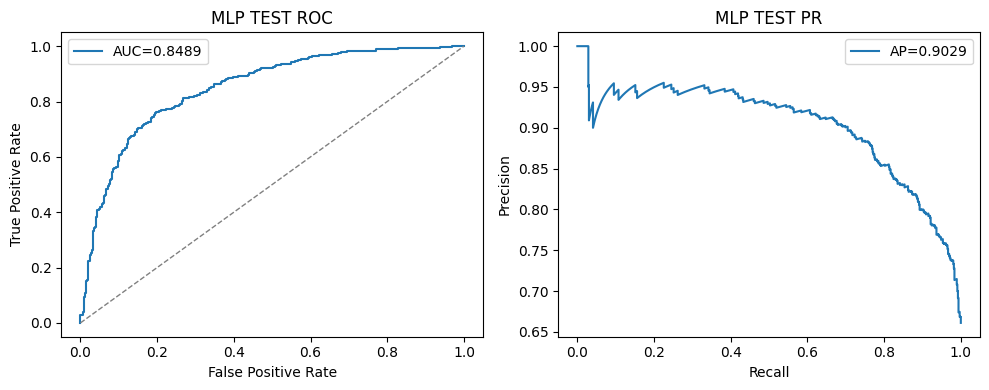

In [34]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
in_dim = X_train.shape[1]
model = train_mlp_classifier(train_loader, test_loader, in_dim=in_dim, device=device, epochs=20)

train_metrics = report_mlp_metrics(model, train_loader, device, "MLP TRAIN")
test_metrics = report_mlp_metrics(model, test_loader, device, "MLP TEST", plot=True)


## XGBoost

In [35]:
# xgb_binary_classifier.py
# XGBoost binary classifier for predicting stable-at-horizon groups

from __future__ import annotations
import numpy as np

try:
    import xgboost as xgb
except ImportError as e:
    raise ImportError("Missing dependency: xgboost. Install with: pip install xgboost") from e


# ---------------------------
# Utilities
# ---------------------------
def loader_to_numpy(loader):
    """
    Convert a PyTorch DataLoader yielding (xb, yb) into numpy arrays.

    Expected:
        xb: (B, D)
        yb: (B, 1) or (B,)

    Returns:
        X: (N, D) float32
        y: (N,) float32
    """
    xs, ys = [], []
    for xb, yb in loader:
        xs.append(xb.detach().cpu().numpy())
        ys.append(yb.detach().cpu().numpy())

    X = np.concatenate(xs, axis=0).astype(np.float32)
    y = np.concatenate(ys, axis=0).reshape(-1).astype(np.float32)
    return X, y


def check_xy(X: np.ndarray, y: np.ndarray, name="data"):
    X = np.asarray(X)
    y = np.asarray(y)

    if X.ndim != 2:
        raise ValueError(f"{name}: X must be 2D (N, D), got shape {X.shape}")
    if y.ndim not in (1, 2):
        raise ValueError(f"{name}: y must be 1D or 2D, got shape {y.shape}")

    y = y.reshape(-1)
    if X.shape[0] != y.shape[0]:
        raise ValueError(f"{name}: X has {X.shape[0]} rows but y has {y.shape[0]} rows")

    if not np.isfinite(X).all():
        raise ValueError(f"{name}: X contains NaN or inf")
    if not np.isfinite(y).all():
        raise ValueError(f"{name}: y contains NaN or inf")

    return X.astype(np.float32), y.astype(np.float32)


# ---------------------------
# Model
# ---------------------------
class XGBBinaryClassifier:
    def __init__(
        self,
        n_estimators: int = 500,
        learning_rate: float = 0.05,
        max_depth: int = 6,
        subsample: float = 0.8,
        colsample_bytree: float = 0.8,
        reg_lambda: float = 1.0,
        reg_alpha: float = 0.0,
        min_child_weight: float = 1.0,
        gamma: float = 0.0,
        random_state: int = 42,
        tree_method: str = "hist",
        n_jobs: int = -1,
    ):
        self.model = xgb.XGBClassifier(
            objective="binary:logistic",
            eval_metric=["logloss", "auc"],
            n_estimators=n_estimators,
            learning_rate=learning_rate,
            max_depth=max_depth,
            subsample=subsample,
            colsample_bytree=colsample_bytree,
            reg_lambda=reg_lambda,
            reg_alpha=reg_alpha,
            min_child_weight=min_child_weight,
            gamma=gamma,
            random_state=random_state,
            tree_method=tree_method,
            n_jobs=n_jobs,
        )

    def fit(
        self,
        X_train: np.ndarray,
        y_train: np.ndarray,
        X_val: np.ndarray | None = None,
        y_val: np.ndarray | None = None,
        verbose: bool = True,
    ):
        X_train, y_train = check_xy(X_train, y_train, name="train")

        eval_set = None
        if X_val is not None and y_val is not None:
            X_val, y_val = check_xy(X_val, y_val, name="val")
            eval_set = [(X_train, y_train), (X_val, y_val)]

        self.model.fit(
            X_train,
            y_train,
            eval_set=eval_set,
            verbose=verbose,
        )
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        X = np.asarray(X, dtype=np.float32)
        if X.ndim != 2:
            raise ValueError(f"X must be 2D (N, D), got shape {X.shape}")

        pred = self.model.predict_proba(X)[:, 1]
        return pred.reshape(-1, 1)


# ---------------------------
# Evaluation
# ---------------------------
def evaluate_binary_classifier(y_true: np.ndarray, y_pred_proba: np.ndarray, prefix="", plot=False):
    metrics = binary_metrics_from_probs(y_true, y_pred_proba)
    print_binary_report(metrics, prefix=prefix)
    if plot:
        plot_binary_curves(metrics, title_prefix=prefix.strip())
    return metrics


# ---------------------------
# Training from arrays
# ---------------------------
def train_xgb_classifier_from_arrays(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
    X_val: np.ndarray | None = None,
    y_val: np.ndarray | None = None,
    plot_test: bool = True,
    **xgb_kwargs,
):
    X_train, y_train = check_xy(X_train, y_train, name="train")
    X_test, y_test = check_xy(X_test, y_test, name="test")

    if X_val is not None and y_val is not None:
        X_val, y_val = check_xy(X_val, y_val, name="val")

    model = XGBBinaryClassifier(**xgb_kwargs)
    model.fit(
        X_train,
        y_train,
        X_val=X_val,
        y_val=y_val,
        verbose=True,
    )

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_metrics = evaluate_binary_classifier(y_train, pred_train, prefix="XGB TRAIN | ")
    test_metrics = evaluate_binary_classifier(y_test, pred_test, prefix="XGB TEST  | ", plot=plot_test)

    return model, train_metrics, test_metrics


# ---------------------------
# Training from PyTorch loaders
# ---------------------------
def train_xgb_classifier_from_loaders(
    train_loader,
    test_loader,
    val_loader=None,
    **xgb_kwargs,
):
    X_train, y_train = loader_to_numpy(train_loader)
    X_test, y_test = loader_to_numpy(test_loader)

    if val_loader is not None:
        X_val, y_val = loader_to_numpy(val_loader)
    else:
        X_val, y_val = None, None

    return train_xgb_classifier_from_arrays(
        X_train, y_train,
        X_test, y_test,
        X_val=X_val, y_val=y_val,
        **xgb_kwargs,
    )


XGB TRAIN | AUC 1.0000 | AP 1.0000 | F1 1.0000 | Acc 1.0000 | Precision 1.0000 | Recall 1.0000
XGB TRAIN | class balance | total 3998 | positive 2645 (0.6616) | negative 1353
XGB TRAIN | confusion matrix [[tn, fp], [fn, tp]] = [[1353, 0], [0, 2645]]
XGB TEST  | AUC 0.8458 | AP 0.9045 | F1 0.8478 | Acc 0.7900 | Precision 0.8136 | Recall 0.8850
XGB TEST  | class balance | total 1000 | positive 661 (0.6610) | negative 339
XGB TEST  | confusion matrix [[tn, fp], [fn, tp]] = [[205, 134], [76, 585]]


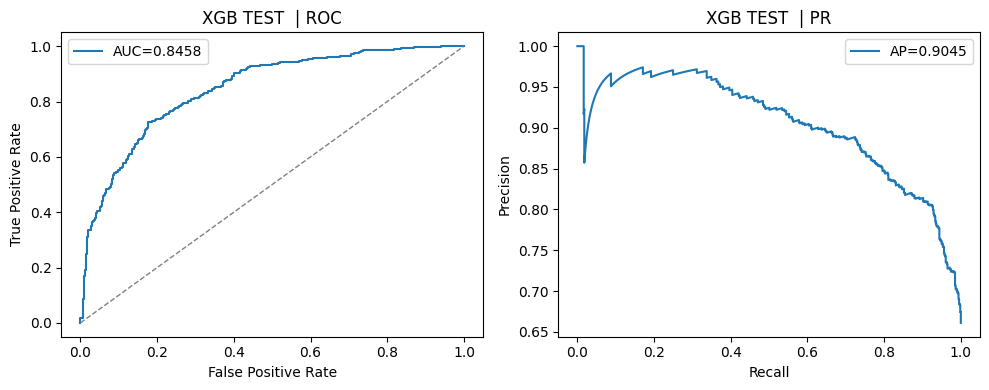

In [36]:
xgb_model, xgb_train_metrics, xgb_test_metrics = train_xgb_classifier_from_loaders(
    train_loader,
    test_loader,
    val_loader=None,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
)


## Evaluation

The cells below help you inspect richer classification metrics and estimate split sensitivity across multiple random seeds.


In [37]:
def run_mlp_seed_sweep(
    X,
    y,
    seeds=(0, 1, 2, 3, 4),
    test_size=1000,
    batch_size=128,
    epochs=100,
    lr=1e-3,
    weight_decay=1e-4,
):
    rows = []
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    for seed in seeds:
        set_random_seed(seed)
        train_idx, test_idx = split_train_test(X, y, test_size=test_size, seed=seed)
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        X_train, X_test, _, _ = standardize_train_test(X_train, X_test)
        train_loader, test_loader = make_loaders(X_train, y_train, X_test, y_test, batch_size=batch_size)

        model = train_mlp_classifier(
            train_loader,
            in_dim=X_train.shape[1],
            device=device,
            lr=lr,
            weight_decay=weight_decay,
            epochs=epochs,
            verbose=False,
        )
        metrics = eval_mlp_classifier(model, test_loader, device)
        rows.append({
            "seed": seed,
            "auc": metrics["auc"],
            "ap": metrics["ap"],
            "f1": metrics["f1"],
            "acc": metrics["acc"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
        })

    result_df = pd.DataFrame(rows)
    display(result_df)
    summary_df = result_df.drop(columns=["seed"]).agg(["mean", "std"])
    display(summary_df)
    return result_df, summary_df


# Example:
# mlp_seed_results, mlp_seed_summary = run_mlp_seed_sweep(X, y, seeds=(0, 1, 2, 3, 4), epochs=100)


In [38]:
mlp_seed_results, mlp_seed_summary = run_mlp_seed_sweep(X, y, seeds=(0, 1, 2, 3, 4), epochs=20)

,seed,auc,ap,f1,acc,precision,recall
0,0,0.848397,0.896691,0.864826,0.814,0.832168,0.900151
1,1,0.827418,0.886971,0.848974,0.794,0.823613,0.875946
2,2,0.851798,0.908836,0.856318,0.801,0.819061,0.897126
3,3,0.817123,0.889951,0.834882,0.769,0.791328,0.883510
4,4,0.817417,0.889783,0.825019,0.765,0.812317,0.838124


,auc,ap,f1,acc,precision,recall
mean,0.832431,0.894446,0.846004,0.788600,0.815697,0.878971
std,0.016695,0.008802,0.016074,0.021031,0.015415,0.024882
